# SardiniaFireAI
### Multi-sensor wildfire detection, event reconstruction and ML-based prioritization

**Technical research report | Sardinia, Italy | June–September 2024**

This notebook summarizes the experimental framework and the main results of SardiniaFireAI. It follows a compact, reproducible reporting format: **data → methods → equations → experiments → results → conclusions**.

> **Scope:** The numeric results reported below are fixed records from completed local experiments. The figures and tables in this notebook are generated from embedded summary values, so they can be reproduced without downloading the original geospatial datasets. Recomputing the underlying experiments requires the SardiniaFireAI repository and its input data.

**Repository:** https://github.com/reimanrey93/SardiniaFireAI  
**Author:** Reiman Alfonso Azcuy

## 1. Objective

Satellite active-fire products provide frequent thermal observations, but individual detections are not equivalent to independent wildfire events. This project assesses how FIRMS observations can be combined into spatiotemporal events, compared against official wildfire records, and ranked according to their likely importance.

The evaluation addresses four questions:

1. **Coverage:** What proportion of officially documented fires can be associated with individual FIRMS detections or reconstructed events?
2. **Size dependence:** How does candidate coverage change with the reference burned area?
3. **Timeliness:** How do preliminary thermal alerts relate to the subsequent identification of spatiotemporal events?
4. **Prioritization:** Can simple thermal indicators or supervised ML rank events by their eventual reference burned area?

The study is a **retrospective proof of concept**, not an independently validated operational alert service.

## 2. Data and study design

| Dataset | Source | Role |
|:--|:--|:--|
| Active-fire detections | NASA FIRMS: VIIRS S-NPP, NOAA-20, NOAA-21; MODIS | Satellite detections, FRP, acquisition time and coordinates |
| Wildfire perimeters | Sardinian regional fire records (CFVA) | Independent burned-area reference and calendar dates |
| Administrative boundaries | geoBoundaries / ISTAT | Spatial definition of Sardinia |

**Study period:** June–September 2024. The CFVA archive used in preprocessing covers additional years, but the results below refer to the selected 2024 season.

The local processing chain included normalization of acquisition timestamps, harmonization of coordinates, an island/coastal spatial mask, and extraction of sensor-specific attributes. Geographic positions were analyzed in **EPSG:32632** for metric operations.

| Quantity | Seasonal sample |
|:--|--:|
| FIRMS detections | **1,385** |
| VIIRS S-NPP | 399 |
| VIIRS NOAA-20 | 415 |
| VIIRS NOAA-21 | 445 |
| MODIS | 126 |
| CFVA reference fires in core period | **792** |

**Reference caveat:** CFVA perimeter dates are not verified ignition times. Spatial or calendar-date agreement is interpreted as a **candidate association**, not necessarily a uniquely confirmed correspondence.

## 3. Methodology

### 3.1. Spatiotemporal event reconstruction

Active-fire observations were clustered using ST-DBSCAN, combining a spatial and a temporal neighborhood.

For detections \(i\) and \(j\), a simplified neighborhood definition is:

\[
j\in\mathcal{N}(i)\quad \Longleftrightarrow \quad
d_{\mathrm{space}}(i,j)\leq \varepsilon_s
\quad \land \quad
|t_i-t_j|\leq \varepsilon_t.
\]

The experiment used:

\[
\varepsilon_s=1500\ \mathrm{m}, \qquad
\varepsilon_t=24\ \mathrm{h}, \qquad
\mathrm{minSamples}=3.
\]

A sparse implementation was used for the seasonal analysis. A chronological replay processed batches of observations grouped by acquisition timestamp; clustering was recomputed using observations available up to each update, with persistent operational event IDs.

### 3.2. Reference association and coverage

A satellite detection is considered a **candidate match** when it falls within a selected spatial tolerance of a reference perimeter and satisfies the calendar-date matching window. The central analysis used a **1 km spatial tolerance** and a **±3-day temporal tolerance**.

Candidate coverage is defined as:

\[
\mathrm{Coverage}=\frac{N_{\mathrm{CFVA\ fires\ with\ candidates}}}
{N_{\mathrm{eligible\ CFVA\ fires}}}\times 100.
\]

It is also evaluated by reference burned-area class.

### 3.3. Preliminary alerts and event identification

Two stages are distinguished:

- **Preliminary:** an individual, not-yet-clustered thermal detection satisfying an alert policy.
- **Confirmed operational event:** an event identified by the ST-DBSCAN algorithm.

For a retrospectively linked event, the precursor lead time is:

\[
\Delta t_{\mathrm{lead}}=t_{\mathrm{event\ identification}}
-t_{\mathrm{first\ preliminary\ alert}}.
\]

Only \(\Delta t_{\mathrm{lead}}>0\) is counted as precursor anticipation. This is **not ignition-to-detection latency**; final event membership is used retrospectively when associating earlier individual alerts with later events.

### 3.4. Machine-learning prioritization

Candidate events were described with sensor, thermal, spatial, and persistence-related features. Provisional one-to-one matches with CFVA supplied a reference area \(A_{\mathrm{ha}}\). Supervised regressors were trained against:

\[
y=\log(1+A_{\mathrm{ha}}), \qquad
\widehat{A}_{\mathrm{ha}}=\max\left(0,\exp(\widehat{y})-1\right).
\]

In the reported experiments, predictions were bounded using training-fold target limits. Five-fold grouped cross-validation kept each `reference_fire_id` in only one test fold.

**Ranking metrics:** Spearman's \(\rho\) evaluates global ordering, while NDCG@10 assesses the highest-ranked events with reference area used as relevance. MAE and RMSE quantify errors in hectares where the model produces area predictions. Count/FRP scores are *ranking proxies*, not hectare predictions.

## 4. Event reconstruction and reference coverage

ST-DBSCAN reconstructed **121 events** from the 1,385 detections: **1,098 detections** were assigned to events and **287** remained as noise. The chronological replay involved **480 acquisition-time updates** and reproduced the final retrospective partition.

### 4.1. Candidate coverage

Of **792 eligible reference fires**, individual FIRMS detections provided candidate matches for **197 (24.87%)**, while clustered events provided candidates for **102 (12.88%)**.

Clustering reduces event duplication, but may remove isolated thermal signals associated with genuine reference fires. Thus, **lower clustered coverage is not automatically evidence of poorer sensor performance**: it is partly the consequence of the chosen minimum cluster size and neighborhood definition.

### 4.2. Coverage by burned-area class

The dependence on reference size is substantial. The largest proportional loss after clustering occurs for small fires, where fewer repeated detections are available.

,Area class,CFVA references,Individual FIRMS,ST-DBSCAN,FIRMS coverage (%),Cluster coverage (%)
0,<10 ha,660,118,42,17.88,6.36
1,10–50 ha,98,50,33,51.02,33.67
2,50–100 ha,14,12,11,85.71,78.57
3,≥100 ha,20,17,16,85.00,80.00


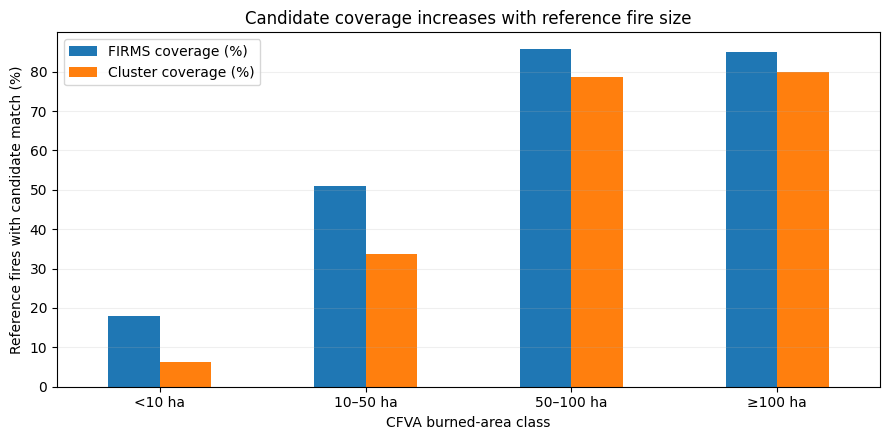

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

coverage = pd.DataFrame({
    "Area class": ["<10 ha", "10–50 ha", "50–100 ha", "≥100 ha"],
    "CFVA references": [660, 98, 14, 20],
    "Individual FIRMS": [118, 50, 12, 17],
    "ST-DBSCAN": [42, 33, 11, 16],
})
coverage["FIRMS coverage (%)"] = (100 * coverage["Individual FIRMS"] / coverage["CFVA references"]).round(2)
coverage["Cluster coverage (%)"] = (100 * coverage["ST-DBSCAN"] / coverage["CFVA references"]).round(2)
display(coverage)

ax = coverage.set_index("Area class")[["FIRMS coverage (%)", "Cluster coverage (%)"]].plot(
    kind="bar", figsize=(9, 4.5), rot=0
)
ax.set_ylabel("Reference fires with candidate match (%)")
ax.set_xlabel("CFVA burned-area class")
ax.set_title("Candidate coverage increases with reference fire size")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### 4.3. Matching sensitivity

Changing the spatial tolerance from **0 to 1.5 km** changes the number of matched CFVA fires. The 1 km tolerance is a comparison convention, **not a proven optimal parameter**. This sensitivity must accompany headline coverage estimates.

,Tolerance (m),Individual FIRMS fires,ST-DBSCAN fires,FIRMS coverage (%),ST-DBSCAN coverage (%)
0,0,84,63,10.61,7.95
1,500,175,93,22.10,11.74
2,1000,197,102,24.87,12.88
3,1500,217,108,27.40,13.64


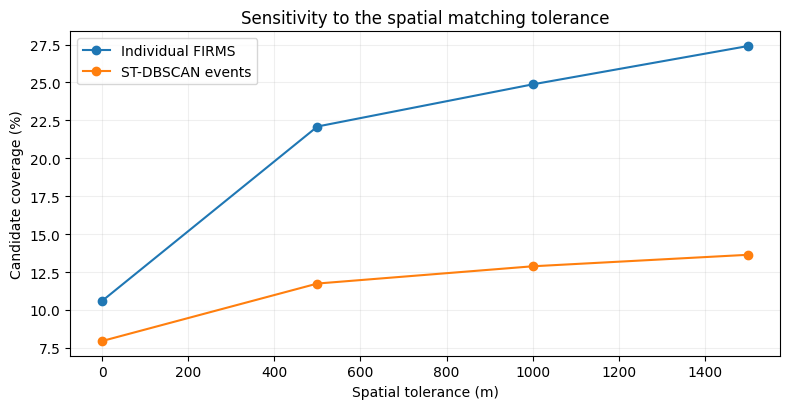

In [2]:
sensitivity = pd.DataFrame({
    "Tolerance (m)": [0, 500, 1000, 1500],
    "Individual FIRMS fires": [84, 175, 197, 217],
    "ST-DBSCAN fires": [63, 93, 102, 108],
})
sensitivity["FIRMS coverage (%)"] = 100 * sensitivity["Individual FIRMS fires"] / 792
sensitivity["ST-DBSCAN coverage (%)"] = 100 * sensitivity["ST-DBSCAN fires"] / 792
display(sensitivity.round(2))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(sensitivity["Tolerance (m)"], sensitivity["FIRMS coverage (%)"], marker="o", label="Individual FIRMS")
ax.plot(sensitivity["Tolerance (m)"], sensitivity["ST-DBSCAN coverage (%)"], marker="o", label="ST-DBSCAN events")
ax.set(xlabel="Spatial tolerance (m)", ylabel="Candidate coverage (%)",
       title="Sensitivity to the spatial matching tolerance")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 5. Preliminary alerts and timeliness

The chronological two-stage replay compared three alert policies: no FRP threshold, a global threshold of **3 MW**, and sensor-specific **P50** thresholds.

| Policy | Preliminary alerts issued | Later incorporated into clusters | Remaining preliminary |
|:--|--:|--:|--:|
| No threshold | 433 | 146 | 287 |
| Global FRP ≥3 MW | 242 | 82 | 160 |
| Product-specific P50 | 217 | 73 | 144 |

These are **detection-level alerts**, not counts of independent fires. The policies were assessed retrospectively, and the product-specific P50 thresholds were derived from the season's final noise detections.

At **event level**, 85/121 events received a precursor under the no-threshold policy. The corresponding figures were 50/121 for the 3 MW threshold and 47/121 for P50. Median lead times among anticipated events were **49**, **34.5**, and **28 minutes**, respectively.

One additional event under the two thresholded policies had its first linked preliminary alert **after** the operational event was already created. This is *not* an anticipatory success.

,Policy,Alerts issued,Later confirmed detections,Events anticipated,Median precursor lead (min),Anticipated events (%)
0,No threshold,433,146,85,49.0,70.2
1,FRP ≥3 MW,242,82,50,34.5,41.3
2,Product P50,217,73,47,28.0,38.8


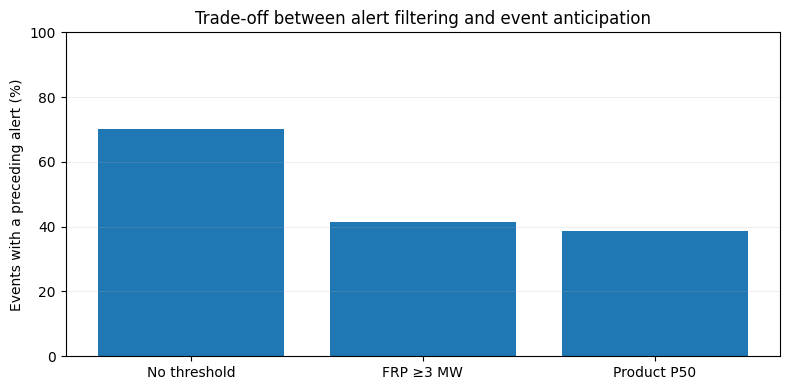

In [3]:
alerts = pd.DataFrame({
    "Policy": ["No threshold", "FRP ≥3 MW", "Product P50"],
    "Alerts issued": [433, 242, 217],
    "Later confirmed detections": [146, 82, 73],
    "Events anticipated": [85, 50, 47],
    "Median precursor lead (min)": [49.0, 34.5, 28.0],
})
alerts["Anticipated events (%)"] = (alerts["Events anticipated"] / 121 * 100).round(1)
display(alerts)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(alerts["Policy"], alerts["Anticipated events (%)"])
ax.set(ylabel="Events with a preceding alert (%)",
       title="Trade-off between alert filtering and event anticipation", ylim=(0, 100))
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Machine-learning experiments

The season-wide event dataset comprises **121 events**, but only **56** have provisional one-to-one CFVA area labels (**A: 16; B: 22; C: 18**). All other events remain *unlabeled*; they are not valid negative training examples.

We evaluated feature families based on non-FRP persistence/spatial descriptors, FRP descriptors, and their combination. The classical supervised models were **Ridge, Random Forest, Histogram Gradient Boosting, and MLP**.

Additional exploratory architectures comprised a small spatial CNN (three-channel FIRMS raster) and a hybrid CNN–MLP. The CNN inputs were very sparse: a median of **four occupied pixels per event** at 250 m resolution.

### 6.1. Predictive performance and ranking

The table below combines the principal reported experiments. Supervised results are five-fold out-of-fold estimates; the FRP + count baseline is a non-trained ranking rule.

,Model,Spearman,NDCG@10,MAE (ha)
0,Count + FRP baseline,0.687,0.826,—
1,Ridge — combined,0.716,0.688,54.28
2,Random Forest — combined,0.647,—,61.36
3,HGB — combined,0.645,—,63.59
4,MLP — combined,0.725,0.809,54.38
5,Spatial CNN,0.171,0.736,60.48
6,Hybrid CNN + MLP,0.269,0.536,63.99


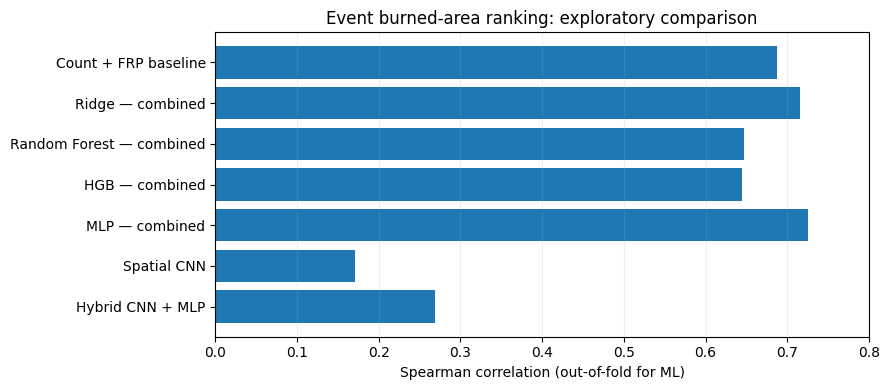

In [4]:
ml = pd.DataFrame({
    "Model": [
        "Count + FRP baseline",
        "Ridge — combined",
        "Random Forest — combined",
        "HGB — combined",
        "MLP — combined",
        "Spatial CNN",
        "Hybrid CNN + MLP",
    ],
    "Spearman": [0.687, 0.716, 0.647, 0.645, 0.725, 0.171, 0.269],
    "NDCG@10": [0.826, 0.688, np.nan, np.nan, 0.809, 0.736, 0.536],
    "MAE (ha)": [np.nan, 54.278, 61.358, 63.593, 54.375, 60.484, 63.99],
})
display(ml.style.format({"Spearman": "{:.3f}", "NDCG@10": "{:.3f}", "MAE (ha)": "{:.2f}"}, na_rep="—"))

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(ml["Model"], ml["Spearman"])
ax.set(xlabel="Spearman correlation (out-of-fold for ML)",
       title="Event burned-area ranking: exploratory comparison", xlim=(0, 0.8))
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

### 6.2. Main statistical result

The combined-feature **MLP reached Spearman \(\rho=0.725\)**, compared with approximately **0.687** for the non-trained count + FRP baseline. Ridge reached **0.716**.

However, the MLP's **NDCG@10 = 0.809** was below the baseline's **0.826**. A paired bootstrap analysis of the MLP's Spearman improvement yielded an approximate **95% interval of −0.083 to +0.173**, which includes zero.

On the **38 higher-quality A+B labels**, MLP Spearman was **0.558**, compared with **0.479** for the baseline; this difference also remained uncertain.

The CNN and hybrid models did not improve global ranking performance. Their poor cross-fold calibration and the sparse spatial evidence limit the present usefulness of raster-only models.

**Interpretation:** ML shows a promising *exploratory improvement in overall rank correlation*, but **there is no conclusive improvement in operational prioritization** on the available sample.

## 7. Discussion

Three findings stand out.

**(1) Event reconstruction and detection coverage represent different goals.** ST-DBSCAN reduces the number of isolated observations and produces coherent event candidates, but the clustering rules discard many small or sparsely observed official fires. A practical monitoring system may benefit from retaining individual alerts alongside confirmed events.

**(2) Fire size strongly conditions observability.** The reference-size analysis reveals much higher thermal candidate coverage for large fires than for fires below 10 ha. Therefore, pooled coverage must be interpreted together with size-stratified coverage and spatial-tolerance sensitivity.

**(3) Supervised prioritization is possible, but the evidence is preliminary.** Persistence and event morphology contain predictive information beyond individual FRP statistics. The combined MLP outperformed the simple ranking rule in global Spearman, but not in NDCG@10, and bootstrap uncertainty was substantial. The comparatively poor CNN results indicate that sparse rasterized detections alone are insufficient for these data.

### Limitations

- Only one four-month season is evaluated here; **no independent year or region** is used as a final test.
- CFVA candidate associations are not equivalent to verified one-to-one detections.
- The CFVA date cannot establish **physical detection latency from ignition**.
- Only **56 provisional area labels** are available for ML, and some quality categories are weaker than others.
- Model selection across repeated experiments can bias the apparent best result.
- Preliminary-alert/event linkage uses final assignments retrospectively.
- No Landsat/Sentinel-2 imagery enters the ML models reported here.

These constraints should be made explicit when comparing SardiniaFireAI with other operational wildfire detection products.

## 8. Conclusions

SardiniaFireAI demonstrates a reproducible multi-sensor framework for reconstructing and evaluating wildfire events in Sardinia. From **1,385 FIRMS detections**, ST-DBSCAN identified **121 event candidates**. Against **792 CFVA reference fires**, individual observations yielded candidates for **197 fires (24.87%)**, compared with **102 (12.88%)** for clustered events under the selected matching criteria.

A two-level alert framework preserved potentially useful early signals: under the unfiltered policy, **85 of the 121 reconstructed events** had a retrospectively linked preliminary alert before event identification, with a **49-minute median lead** among those events.

Machine learning added a preliminary ability to rank events by reference burned area: a combined-feature MLP reached **Spearman 0.725**, versus **0.687** for a count + FRP baseline. Nevertheless, the improvement is **not statistically established**, and the simple rule retained better NDCG@10. Spatial CNN experiments did not provide an additional advantage.

**Overall conclusion:** combining individual thermal signals, incremental spatiotemporal event reconstruction, reference-based evaluation, and transparent ranking baselines is more informative than relying on clustering or ML alone. Independent cross-year validation and better verified labels are the main priorities for future work.

## 9. Reproducing the experiments

The repository contains the source code, configurations, and tests:

**https://github.com/reimanrey93/SardiniaFireAI**

After obtaining the official source data and preparing the corresponding seasonal Parquet inputs, the locally developed experimental scripts include:

```bash
python -m pip install -e ".[dev]"
python -m pip install scipy torch
python -m ruff check src tests scripts
python -m pytest -q

# Historical replay (requires prepared seasonal Parquet files)
python scripts/experiments/run_incremental.py
python scripts/experiments/run_alert_lifecycle.py

# ML (requires the season-wide labeled ranking dataset)
python scripts/experiments/run_ml_feature_ablation.py
python scripts/experiments/run_spatial_dl.py
python scripts/experiments/run_hybrid_cnn.py
```

**Important:** Some experimental modules were initially developed locally and must be committed before fresh GitHub clones can reproduce these commands. Some scripts refuse to overwrite existing outputs. This notebook **reproduces the displayed summary figures and tables**, but does **not** automatically reconstruct the underlying scientific results from raw data.

### Data / reproducibility references
- NASA FIRMS: https://firms.modaps.eosdis.nasa.gov/
- geoBoundaries: https://www.geoboundaries.org/
- SardiniaFireAI: https://github.com/reimanrey93/SardiniaFireAI

This report is a preliminary technical study based on the experiments completed as of October 2026.